# EDA of the raw data

A look at the four source files in `data/` before they go into the datamart: how the rows are spread over
`snapshot_date`, what the loans and the label look like, and the distributions and data quality of the features.
The main charts are also saved to `analysis/eda/`.

In [1]:
import os

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

BLUE, ORANGE, GREY, LIGHT_GREY = "#2a78d6", "#eb6834", "#52514e", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": LIGHT_GREY,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.labelcolor": GREY, "axes.titlesize": 11, "axes.titlelocation": "left", "legend.frameon": False,
    "font.size": 10,
})
OUT = "analysis/eda"
os.makedirs(OUT, exist_ok=True)


def save(fig, name, title):
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout()
    fig.savefig(f"{OUT}/{name}.png", dpi=150, bbox_inches="tight")


def month_axis(ax, end="2025-11-25"):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    ax.set_xlim(pd.Timestamp("2022-12-10"), pd.Timestamp(end))


def monthly_bars(ax, counts, colour=BLUE, end="2025-11-25"):
    ax.bar(pd.to_datetime(counts.index), counts.values, width=24, color=colour)
    month_axis(ax, end)


APP_END = "2025-01-25"  # last application month

In [2]:
lms = pd.read_csv("data/lms_loan_daily.csv", parse_dates=["loan_start_date", "snapshot_date"])
clickstream = pd.read_csv("data/feature_clickstream.csv", parse_dates=["snapshot_date"])
attributes = pd.read_csv("data/features_attributes.csv", parse_dates=["snapshot_date"])
financials = pd.read_csv("data/features_financials.csv", parse_dates=["snapshot_date"])
files = {"lms_loan_daily": lms, "feature_clickstream": clickstream,
         "features_attributes": attributes, "features_financials": financials}

pd.DataFrame([{
    "file": name, "rows": len(df), "columns": df.shape[1], "customers": df["Customer_ID"].nunique(),
    "first snapshot": df["snapshot_date"].min().date(), "last snapshot": df["snapshot_date"].max().date(),
    "months": df["snapshot_date"].nunique(), "rows per customer": round(len(df) / df["Customer_ID"].nunique(), 1),
} for name, df in files.items()])

,file,rows,columns,customers,first snapshot,last snapshot,months,rows per customer
0,lms_loan_daily,137500,11,12500,2023-01-01,2025-11-01,35,11.0
1,feature_clickstream,215376,22,8974,2023-01-01,2024-12-01,24,24.0
2,features_attributes,12500,6,12500,2023-01-01,2025-01-01,25,1.0
3,features_financials,12500,22,12500,2023-01-01,2025-01-01,25,1.0


## 1. Rows per `snapshot_date`

Each file has one partition per month. The four files cover different months and have very different shapes.

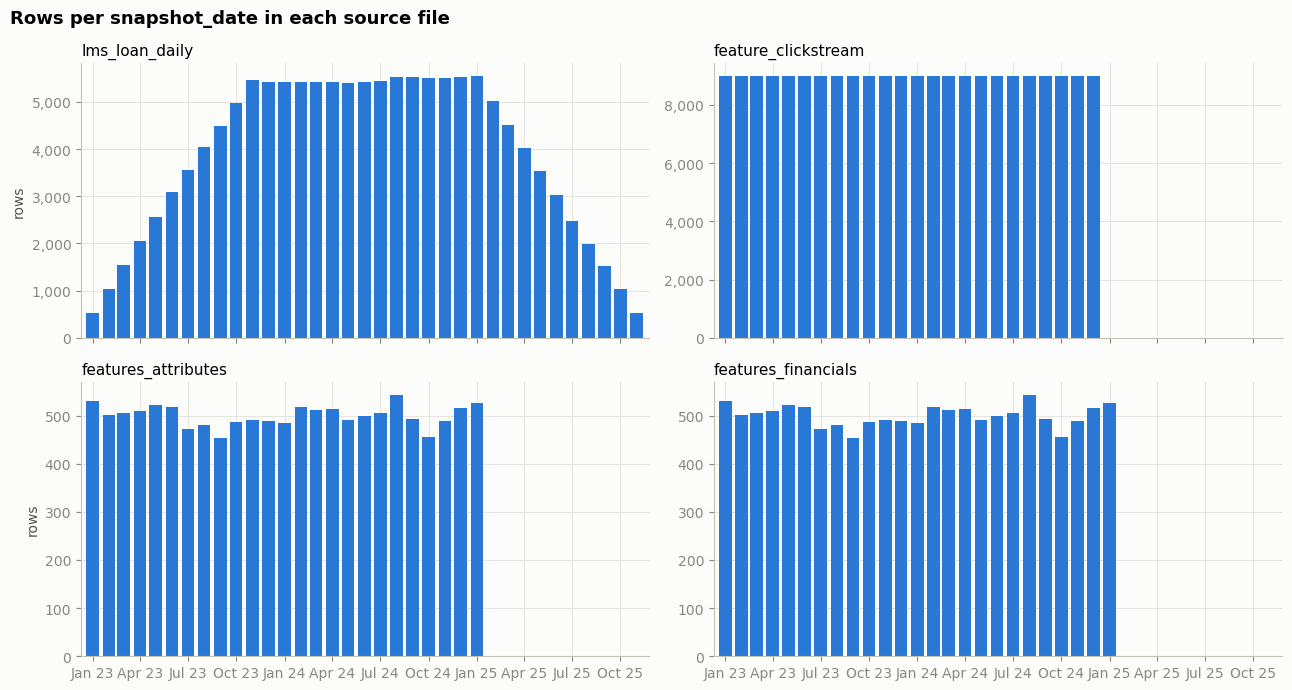

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, (name, df) in zip(axes.flat, files.items()):
    monthly_bars(ax, df["snapshot_date"].value_counts().sort_index())
    ax.set_title(name)
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
for ax in axes[:, 0]:
    ax.set_ylabel("rows")
save(fig, "01_rows_per_snapshot_date", "Rows per snapshot_date in each source file")

- **lms_loan_daily**: one row per loan per month while the loan is open. Loans start every month from Jan 2023 to
  Jan 2025 and run for 10 instalments, so the row count builds up for 11 months, stays flat at about 5,400
  (11 open cohorts) and runs off after Jan 2025 until Nov 2025.
- **feature_clickstream**: exactly 8,974 rows every month from Jan 2023 to Dec 2024. It is a fixed panel of
  customers tracked every month, not linked to when they apply.
- **features_attributes / features_financials**: about 500 rows per month from Jan 2023 to Jan 2025, one row per
  customer, dated the month the customer applied (checked below).

In [4]:
applications = lms.drop_duplicates("loan_id")[["loan_id", "Customer_ID", "loan_start_date", "tenure", "loan_amt"]]
start_of = applications.set_index("Customer_ID")["loan_start_date"]
for name, df in (("features_attributes", attributes), ("features_financials", financials)):
    same = (df["snapshot_date"].values == start_of.reindex(df["Customer_ID"]).values).mean()
    print(f"{name}: snapshot_date == loan_start_date for {same:.0%} of customers")
print("loans per customer:", lms.groupby("Customer_ID")["loan_id"].nunique().max())
print("loan_amt values:", applications["loan_amt"].unique(), "| tenure values:", applications["tenure"].unique())

features_attributes: snapshot_date == loan_start_date for 100% of customers
features_financials: snapshot_date == loan_start_date for 100% of customers
loans per customer: 1
loan_amt values: [10000] | tenure values: [10]


## 2. Applications and the label

Every customer has exactly one loan of 10,000 over 10 instalments, so the model only has to rank customers by risk.
The label is the same as in the label store: **30+ days past due at 6 months on book** (`installment_num == 6`).

labelled loans: 12,500  |  default rate: 28.8%


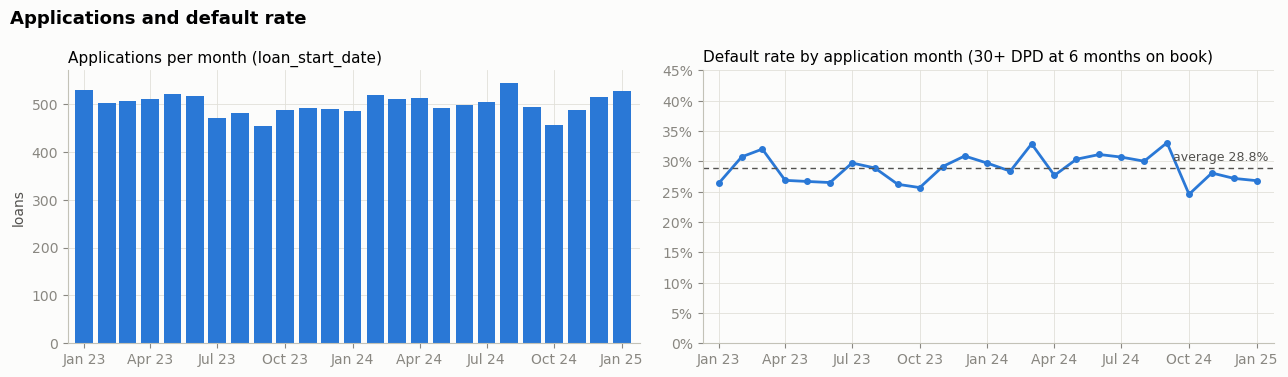

In [5]:
mob6 = lms[lms["installment_num"] == 6].copy()


def days_past_due(row):
    if row["overdue_amt"] <= 0:
        return 0
    missed = int(np.ceil(row["overdue_amt"] / row["due_amt"]))
    return (row["snapshot_date"] - (row["snapshot_date"] - pd.DateOffset(months=missed))).days


mob6["dpd"] = mob6.apply(days_past_due, axis=1)
mob6["label"] = (mob6["dpd"] >= 30).astype(int)
labels = mob6[["Customer_ID", "loan_start_date", "label"]]
print(f"labelled loans: {len(labels):,}  |  default rate: {labels['label'].mean():.1%}")

by_month = labels.groupby("loan_start_date")["label"].agg(["size", "mean"])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
monthly_bars(ax1, by_month["size"], end=APP_END)
ax1.set_title("Applications per month (loan_start_date)")
ax1.set_ylabel("loans")
ax2.plot(pd.to_datetime(by_month.index), by_month["mean"], color=BLUE, linewidth=2, marker="o", markersize=4)
ax2.axhline(labels["label"].mean(), color=GREY, linewidth=1, linestyle=(0, (4, 3)))
ax2.annotate(f"average {labels['label'].mean():.1%}", (1, labels["label"].mean()), xycoords=("axes fraction", "data"),
             xytext=(-4, 6), textcoords="offset points", ha="right", fontsize=9, color=GREY)
month_axis(ax2, APP_END)
ax2.set_ylim(0, 0.45)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax2.set_title("Default rate by application month (30+ DPD at 6 months on book)")
save(fig, "02_applications_and_default_rate", "Applications and default rate")

About 500 applications a month and a default rate between 25% and 33% with no trend. The classes are not badly
imbalanced, so no resampling is needed. A loan applied in month M only gets its label in month M+6, so the last
labels (applications of Jan 2025) arrive in Jul 2025.

## 3. Clickstream coverage of applicants

Does each applicant have clickstream data in the month they apply?

loan_start_date,2023-01-01,2023-02-01,2023-03-01,2023-04-01,2023-05-01,2023-06-01,2023-07-01,2023-08-01,2023-09-01,2023-10-01,2023-11-01,2023-12-01,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01
coverage,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,0%,0%,0%,0%,0%,0%,0%


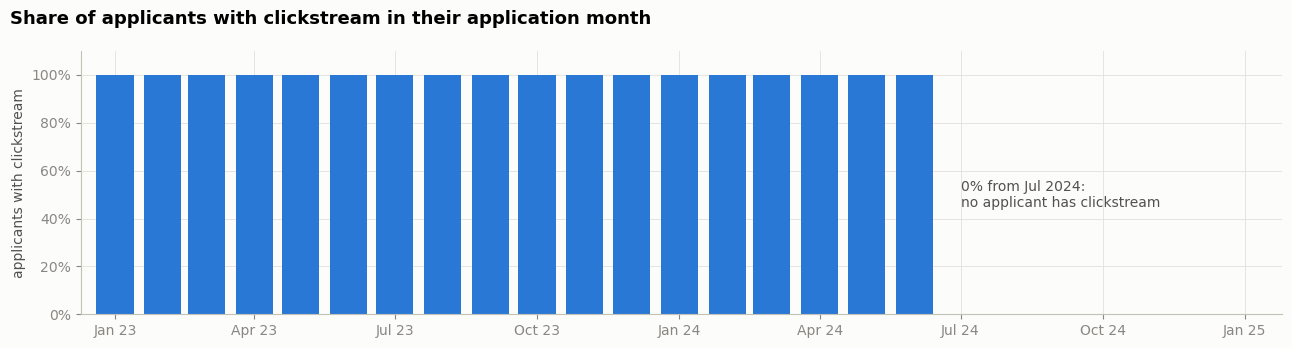

In [6]:
has_clickstream = set(zip(clickstream["Customer_ID"], clickstream["snapshot_date"]))
applications["has_clickstream"] = [(c, d) in has_clickstream
                                   for c, d in zip(applications["Customer_ID"], applications["loan_start_date"])]
coverage = applications.groupby("loan_start_date")["has_clickstream"].mean()

fig, ax = plt.subplots(figsize=(13, 3.5))
monthly_bars(ax, coverage, end=APP_END)
ax.set_ylim(0, 1.1)
ax.annotate("0% from Jul 2024:\nno applicant has clickstream", (pd.Timestamp("2024-07-01"), 0.5),
            fontsize=10, color=GREY, va="center")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.set_ylabel("applicants with clickstream")
save(fig, "03_clickstream_coverage", "Share of applicants with clickstream in their application month")
coverage.map("{:.0%}".format).to_frame("coverage").T

**All applicants up to Jun 2024 have clickstream, and none from Jul 2024 on.** The clickstream panel only contains
the 8,974 customers who applied up to Jun 2024. A model trained on clickstream never sees a missing value in
training, so it breaks for every later applicant. This is why the models leave clickstream out
(`EXCLUDED_FEATURE_PREFIXES` in `utils/model_train.py`).

## 4. Attributes

Age with a trailing '_': 637  |  outside 1-100: 319
Occupation '_______' (missing): 880
SSN not in ###-##-#### format: 703  (Name and SSN are not used as features)


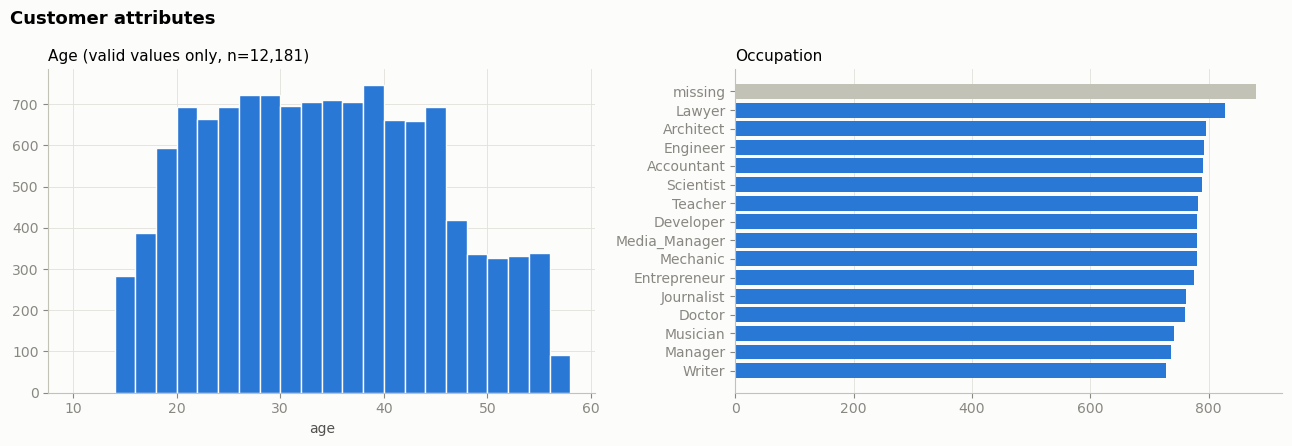

In [7]:
age_raw = attributes["Age"].astype(str)
age = pd.to_numeric(age_raw.str.replace("_", "", regex=False), errors="coerce")
valid_age = age.between(1, 100)
print(f"Age with a trailing '_': {age_raw.str.contains('_').sum()}  |  outside 1-100: {(~valid_age).sum()}")
print(f"Occupation '_______' (missing): {(attributes['Occupation'] == '_______').sum()}")
print(f"SSN not in ###-##-#### format: {(~attributes['SSN'].str.match(r'^\d{3}-\d{2}-\d{4}$')).sum()}"
      "  (Name and SSN are not used as features)")

occupation = attributes["Occupation"].replace("_______", "missing").value_counts().sort_values()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.hist(age[valid_age], bins=range(10, 60, 2), color=BLUE, edgecolor="#fcfcfb")
ax1.set_title(f"Age (valid values only, n={valid_age.sum():,})")
ax1.set_xlabel("age")
ax2.barh(occupation.index, occupation.values,
         color=[LIGHT_GREY if o == "missing" else BLUE for o in occupation.index])
ax2.set_title("Occupation")
ax2.grid(axis="y", visible=False)
save(fig, "04_attributes", "Customer attributes")

## 5. Financials

Many numeric columns are stored as text because of dirty values (`"52312.68_"`, `"_"`, `"__10000__"`) and there are
impossible values such as hundreds of bank accounts. The silver layer cleans them; the table counts how many rows
are affected.

In [8]:
numeric_cols = ["Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate",
                "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment", "Changed_Credit_Limit",
                "Num_Credit_Inquiries", "Outstanding_Debt", "Credit_Utilization_Ratio", "Total_EMI_per_month",
                "Amount_invested_monthly", "Monthly_Balance"]
valid_range = {"Num_Bank_Accounts": (0, 15), "Num_Credit_Card": (0, 15), "Interest_Rate": (0, 50),
               "Num_of_Loan": (0, 15), "Num_of_Delayed_Payment": (0, 30), "Num_Credit_Inquiries": (0, 20)}

clean = pd.DataFrame({"Customer_ID": financials["Customer_ID"]})
quality = []
for c in numeric_cols:
    raw = financials[c].astype(str)
    starts_with_underscore = raw.str.startswith("_")
    value = pd.to_numeric(raw.str.replace("_", "", regex=False), errors="coerce").where(~starts_with_underscore)
    low, high = valid_range.get(c, (-np.inf, np.inf))
    out_of_range = value.notna() & ~value.between(low, high)
    quality.append({"column": c, "trailing _ (fixed)": int((raw.str.contains("_") & ~starts_with_underscore).sum()),
                    "missing or garbage": int(value.isna().sum()), "out of range": int(out_of_range.sum())})
    clean[c] = value.where(~out_of_range)
quality = pd.DataFrame(quality).set_index("column")
quality[quality.sum(axis=1) > 0]

,trailing _ (fixed),missing or garbage,out of range
column,,,
Annual_Income,859,0,0
Num_Bank_Accounts,0,0,171
Num_Credit_Card,0,0,296
Interest_Rate,0,0,270
Num_of_Loan,623,0,567
Num_of_Delayed_Payment,374,0,189
Changed_Credit_Limit,0,254,0
Num_Credit_Inquiries,0,0,195
Outstanding_Debt,139,0,0


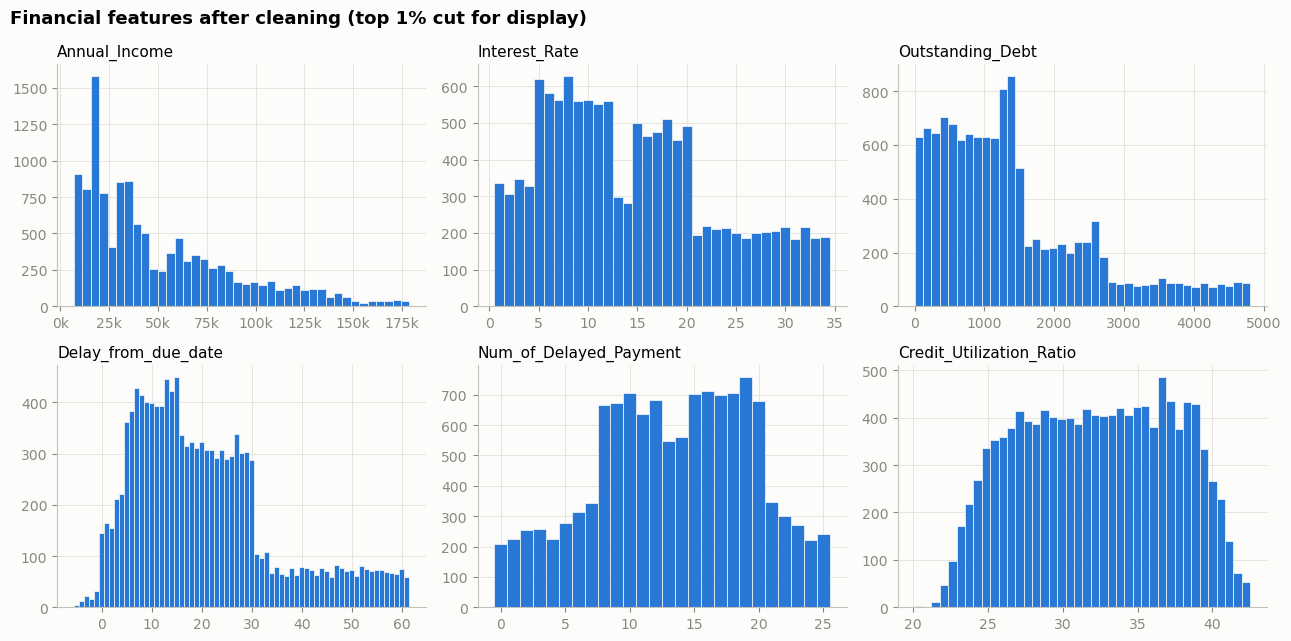

In [9]:
show = ["Annual_Income", "Interest_Rate", "Outstanding_Debt", "Delay_from_due_date",
        "Num_of_Delayed_Payment", "Credit_Utilization_Ratio"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.flat, show):
    values = clean[c].dropna()
    values = values[values <= values.quantile(0.99)]  # cut the top 1% so the shape is visible
    whole = np.allclose(values, values.round()) and values.max() - values.min() <= 80
    bins = np.arange(values.min(), values.max() + 2) - 0.5 if whole else 40
    ax.hist(values, bins=bins, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
    ax.set_title(c)
    if values.max() >= 10_000:
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
save(fig, "05_financials_numeric", "Financial features after cleaning (top 1% cut for display)")

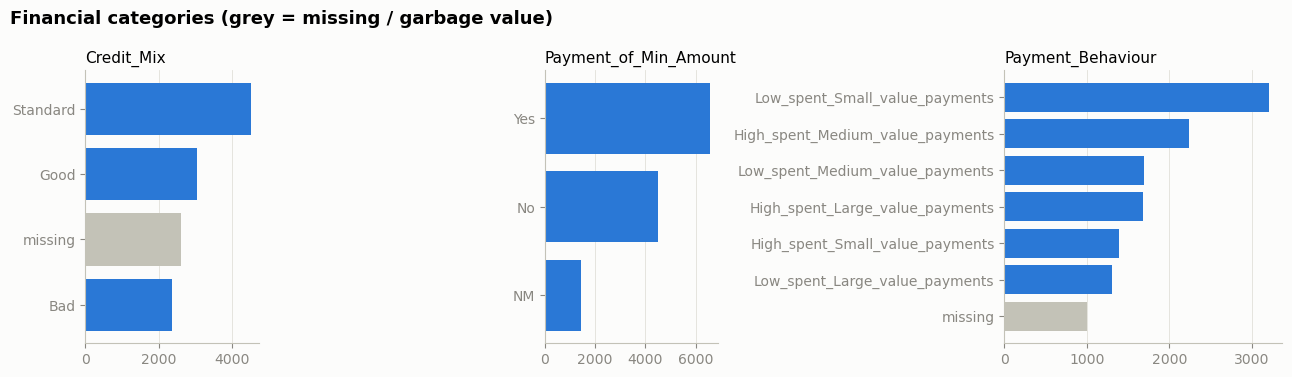

In [10]:
categorical = {
    "Credit_Mix": financials["Credit_Mix"].replace("_", "missing"),
    "Payment_of_Min_Amount": financials["Payment_of_Min_Amount"],
    "Payment_Behaviour": financials["Payment_Behaviour"].replace("!@9#%8", "missing"),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.6]})
for ax, (name, values) in zip(axes, categorical.items()):
    counts = values.value_counts().sort_values()
    ax.barh(counts.index, counts.values, color=[LIGHT_GREY if v == "missing" else BLUE for v in counts.index])
    ax.set_title(name)
    ax.grid(axis="y", visible=False)
save(fig, "06_financials_categorical", "Financial categories (grey = missing / garbage value)")

## 6. Clickstream features `fe_1` .. `fe_20`

missing values: 0


,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20
count,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0,215376.0
mean,101.4,103.1,104.3,105.6,107.0,103.2,107.1,110.7,114.4,117.8,99.6,99.8,100.4,100.0,99.6,99.9,100.1,100.1,100.3,100.0
std,99.8,99.9,100.6,100.3,100.7,100.3,100.3,100.2,100.2,100.8,100.3,100.6,100.9,101.1,101.1,100.8,101.3,102.2,102.7,103.6
min,-378.0,-356.0,-399.0,-307.0,-343.0,-321.0,-368.0,-361.0,-328.0,-317.0,-375.0,-344.0,-355.0,-394.0,-351.0,-342.0,-329.0,-344.0,-401.0,-354.0
25%,34.0,36.0,36.0,38.0,39.0,36.0,39.0,43.0,47.0,50.0,32.0,32.0,33.0,32.0,31.0,32.0,32.0,31.0,31.0,30.0
50%,102.0,103.0,104.0,106.0,107.0,103.0,107.0,111.0,115.0,118.0,100.0,100.0,101.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
75%,169.0,171.0,172.0,173.0,175.0,171.0,174.0,179.0,182.0,186.0,167.0,168.0,168.0,168.0,168.0,168.0,169.0,169.0,170.0,170.0
max,541.0,560.0,583.0,562.0,570.0,565.0,537.0,573.0,577.0,537.0,613.0,550.0,530.0,583.0,597.0,554.0,516.0,551.0,560.0,547.0


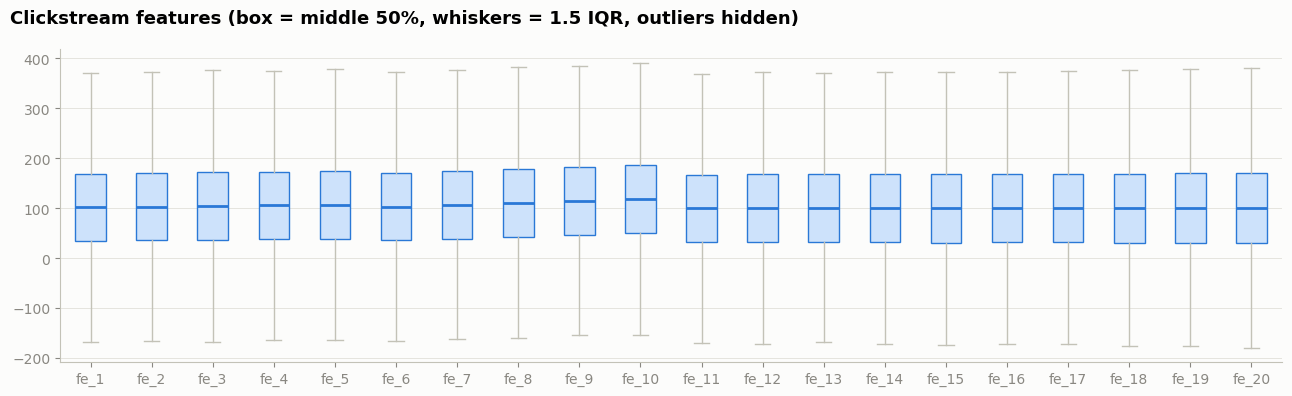

In [11]:
fe_cols = [f"fe_{i}" for i in range(1, 21)]
print(f"missing values: {clickstream[fe_cols].isna().sum().sum()}")
fig, ax = plt.subplots(figsize=(13, 4))
ax.boxplot([clickstream[c] for c in fe_cols], tick_labels=fe_cols, showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#cde2fb", "edgecolor": BLUE}, medianprops={"color": BLUE, "linewidth": 2},
           whiskerprops={"color": LIGHT_GREY}, capprops={"color": LIGHT_GREY})
ax.grid(axis="x", visible=False)
save(fig, "07_clickstream_features", "Clickstream features (box = middle 50%, whiskers = 1.5 IQR, outliers hidden)")
clickstream[fe_cols].describe().round(1)

## 7. Default rate by a few features

Joining the financials (dated at application) to the label shows which features separate good and bad loans.

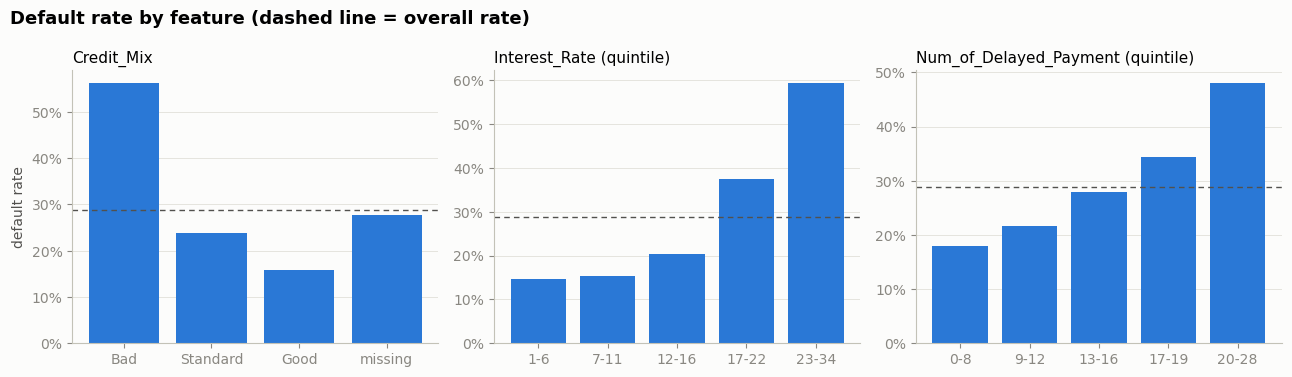

In [12]:
data = clean.merge(financials[["Customer_ID", "Credit_Mix"]], on="Customer_ID").merge(labels, on="Customer_ID")
panels = {
    "Credit_Mix": data["Credit_Mix"].replace("_", "missing"),
    "Interest_Rate (quintile)": pd.qcut(data["Interest_Rate"], 5),
    "Num_of_Delayed_Payment (quintile)": pd.qcut(data["Num_of_Delayed_Payment"], 5, duplicates="drop"),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, group) in zip(axes, panels.items()):
    rate = data.groupby(group, observed=True)["label"].mean()
    if name == "Credit_Mix":
        rate = rate.reindex(["Bad", "Standard", "Good", "missing"])
        names = list(rate.index)
    else:  # integer features: (6.0, 11.0] -> 7-11
        names = [f"{int(np.floor(i.left)) + 1}-{int(i.right)}" for i in rate.index]
    ax.bar(names, rate.values, color=BLUE)
    ax.axhline(data["label"].mean(), color=GREY, linewidth=1, linestyle=(0, (4, 3)))
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    ax.set_title(name)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("default rate")
save(fig, "08_default_rate_by_feature", "Default rate by feature (dashed line = overall rate)")

## Takeaways

- **Time coverage differs per file.** Applications and their features run from Jan 2023 to Jan 2025
  (25 months, about 500 a month). The loan ledger runs to Nov 2025, so 6-month labels exist from Jul 2023 to
  Jul 2025. Clickstream runs from Jan 2023 to Dec 2024, but only for a fixed panel of 8,974 customers.
- **Features are dated at application.** For every customer, the attributes and financials `snapshot_date` equals
  `loan_start_date`. Training must join a label (month M+6) to the features of month M; joining on the label month
  would leak.
- **The label is stable.** 28.8% default overall and 25% to 33% per month with no trend, so no resampling.
- **Clickstream stops for new applicants.** 100% coverage up to Jun 2024 and 0% after, so it is left out of the
  models.
- **Every loan is the same product.** 10,000 over 10 instalments, so loan amount and tenure carry no information.
- **Dirty data is common, and the silver layer cleans it.** Age has 637 values with a trailing `_` and 319 outside
  1-100. Occupation is missing for 880 customers, Credit_Mix for 2,611 and Payment_Behaviour for 998. Several count
  columns have impossible values, e.g. 567 rows with `Num_of_Loan` outside 0-15.
- **There are clear signals.** Default rate is 56% for a Bad credit mix vs 16% for Good, 59% in the top interest rate
  quintile vs 15% in the bottom, and rises from 18% to 48% with the number of delayed payments.